# ZelaCidade — 01. O problema nos dados reais do SP156

**Fonte:** Dados do SP156 - Solicitações, Prefeitura de São Paulo (dados.prefeitura.sp.gov.br), licença **Creative Commons CC0**, 2º e 3º trimestres de 2026.

Este notebook lê as tabelas geradas por `src/zela/dados.py` em `data/processed/`. Os CSVs brutos (~100 MB cada) ficam fora do Git e são baixados pelo próprio script. O texto escrito pelo cidadão **não** é publicado pela Prefeitura; por isso aqui só há categorias, datas, órgãos e locais.

**Perguntas:**
1. Quanto pedido de zeladoria a cidade recebe, e de que tipo?
2. Quanto tempo leva para resolver?
3. Quanto retrabalho existe com pedidos repetidos?
4. O encaminhamento depende do lugar?

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC = RAIZ / "data" / "processed"
FIG = RAIZ / "docs" / "evidencias"
FIG.mkdir(parents=True, exist_ok=True)

categorias = pd.read_csv(PROC / "categorias_sp156.csv")
duplicidade = pd.read_csv(PROC / "duplicidade_sp156.csv")
roteamento = pd.read_csv(PROC / "roteamento_sp156.csv")
mapa = pd.read_csv(PROC / "mapa_sp156.csv")
curto = {"buraco": "Buraco", "entulho": "Entulho", "arvore": "Árvore", "calcada": "Calçada", "drenagem": "Drenagem",
         "varricao": "Varrição", "coleta": "Coleta", "capinacao": "Mato alto", "barulho": "Barulho", "veiculo": "Veículo",
         "sinalizacao": "Sinalização", "pragas": "Pragas"}
categorias["nome"] = categorias["categoria"].map(curto)
total_pedidos = f"{categorias['pedidos_2_trimestres'].sum():,}".replace(",", ".")
print(f"Pedidos de zeladoria em 12 categorias, abr–set/2026: {total_pedidos}")
categorias[["nome", "pedidos_2_trimestres", "mediana_dias", "p80_dias", "pct_ainda_aberto_t2", "orgao_mais_frequente", "pct_orgao_mais_frequente"]]

Pedidos de zeladoria em 12 categorias, abr–set/2026: 316.522


,nome,pedidos_2_trimestres,mediana_dias,p80_dias,pct_ainda_aberto_t2,orgao_mais_frequente,pct_orgao_mais_frequente
0,Entulho,71382,1.0,2.0,3.2,INTEGRAÇÃO-AMLURB-FLIP,95.6
1,Buraco,53600,6.0,20.0,31.8,INTEGRAÇÃO-SMGI/SGZ,95.8
2,Árvore,33404,15.0,40.0,22.2,INTEGRAÇÃO-SMGI/SGZ,100.0
3,Barulho,30318,29.0,53.0,66.4,INTEGRACAO-SGF,100.0
4,Calçada,24558,14.0,48.0,56.4,INTEGRAÇÃO-SMGI/SGZ,74.8
5,Veículo,24069,35.0,61.0,77.5,INTEGRACAO-SGF,100.0
6,Varrição,20240,1.0,2.0,3.2,INTEGRAÇÃO-AMLURB-FLIP,100.0
7,Mato alto,17518,1.0,11.0,5.1,INTEGRAÇÃO-AMLURB-FLIP,51.3
8,Drenagem,16923,3.0,19.0,19.2,INTEGRAÇÃO-AMLURB-FLIP,60.7
9,Pragas,12138,18.0,42.0,13.8,INTEGRACAO-SISCOZ,10.9


## 1 e 2. Volume e tempo de resposta

O prazo é medido só no 2º trimestre, entre pedidos já finalizados. Usar o 3º trimestre puxaria a mediana para baixo: os pedidos longos daquele período ainda estão abertos (viés de censura). Mesmo assim, o valor real tende a ser **maior** que o mostrado, porque os pedidos ainda abertos não entram na conta.

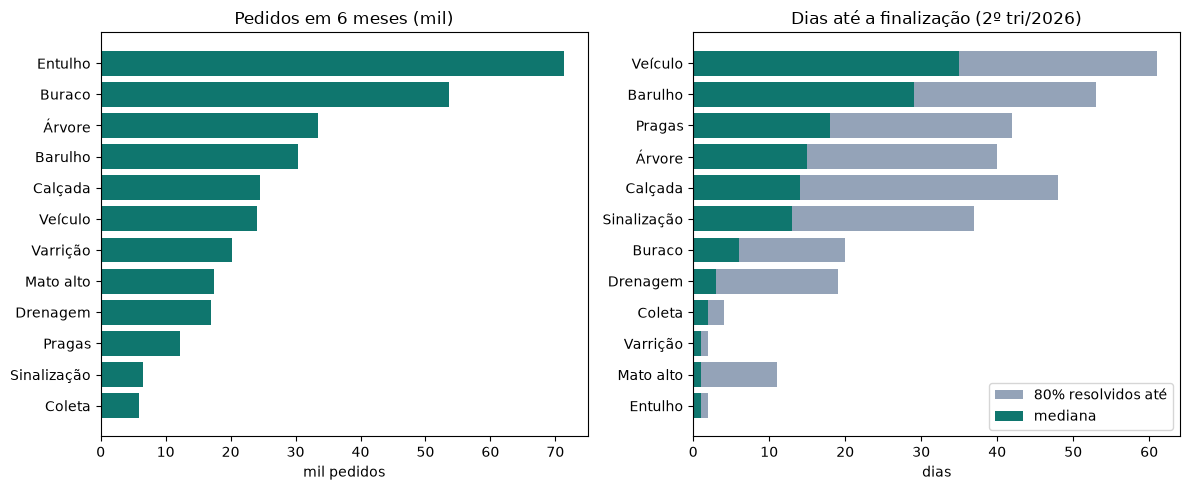

In [2]:
ordem = categorias.sort_values("pedidos_2_trimestres")
fig, eixos = plt.subplots(1, 2, figsize=(12, 5))
eixos[0].barh(ordem["nome"], ordem["pedidos_2_trimestres"] / 1000, color="#0f766e")
eixos[0].set(title="Pedidos em 6 meses (mil)", xlabel="mil pedidos")
ordem = categorias.sort_values("mediana_dias")
eixos[1].barh(ordem["nome"], ordem["p80_dias"], color="#94a3b8", label="80% resolvidos até")
eixos[1].barh(ordem["nome"], ordem["mediana_dias"], color="#0f766e", label="mediana")
eixos[1].set(title="Dias até a finalização (2º tri/2026)", xlabel="dias")
eixos[1].legend()
fig.tight_layout()
fig.savefig(FIG / "dados_volume_prazo.png", dpi=130)
plt.show()

**Leitura:** a desigualdade é grande. Entulho e varrição se resolvem em 1 dia na mediana; veículo abandonado leva 35 dias e barulho, 29. Nessas duas categorias, a maioria dos pedidos do 2º trimestre ainda estava aberta ao final do período. Um prazo único para tudo não serve: o ZelaCidade usa o **p80 real de cada categoria** como prazo de referência para escalar atrasos.

## 3. Retrabalho: o mesmo problema relatado várias vezes

Conta um pedido como repetido quando outro da mesma categoria, no mesmo ponto (coordenada com 4 casas, cerca de 11 m), já estava aberto. É uma estimativa: pedidos no mesmo endereço geocodificado podem ser problemas diferentes, e pedidos a 20 m do anterior ficam de fora.

Pedidos repetidos enquanto o anterior seguia aberto: 58.161 de 316.510 (18,4%)


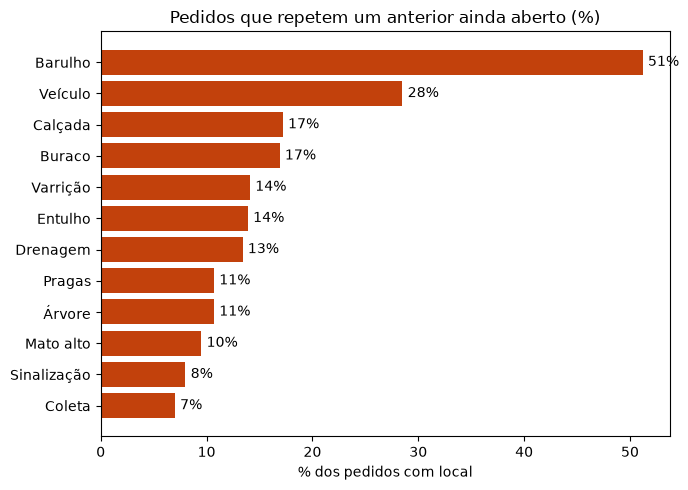

In [3]:
dup = duplicidade.assign(nome=duplicidade["categoria"].map(curto)).sort_values("pct_repetidos")
total_rep = duplicidade["repetidos_com_anterior_aberto"].sum()
total = duplicidade["pedidos_com_local"].sum()
print(f"Pedidos repetidos enquanto o anterior seguia aberto: {total_rep:,} de {total:,}".replace(",", ".") + f" ({total_rep / total:.1%})".replace(".", ","))
fig, eixo = plt.subplots(figsize=(7, 5))
eixo.barh(dup["nome"], dup["pct_repetidos"], color="#c2410c")
eixo.set(title="Pedidos que repetem um anterior ainda aberto (%)", xlabel="% dos pedidos com local")
for y, v in enumerate(dup["pct_repetidos"]):
    eixo.text(v + 0.5, y, f"{v:.0f}%", va="center")
fig.tight_layout()
fig.savefig(FIG / "dados_repetidos.png", dpi=130)
plt.show()

**Leitura:** em barulho, metade dos pedidos repete um anterior ainda aberto (o mesmo bar, a mesma festa). Cada repetição é um chamado a mais para triar e encaminhar. O ZelaCidade agrupa relatos da mesma categoria a até 30 m de um pedido aberto: em vez de abrir um chamado novo, soma um "apoio", que também serve de sinal de prioridade.

## 4. O encaminhamento depende do lugar

Para cada categoria, quanto o órgão mais comum concentra do atendimento, e em quantas subprefeituras outro órgão é o principal.

In [4]:
conc = []
for cat, g in roteamento.groupby("categoria"):
    principal = g["orgao"].value_counts()
    conc.append({"categoria": curto[cat], "subprefeituras": len(g), "orgaos_distintos": g["orgao"].nunique(),
                 "orgao_principal": principal.index[0], "subprefeituras_com_outro_orgao": len(g) - principal.iloc[0]})
pd.DataFrame(conc).sort_values("orgaos_distintos", ascending=False)

,categoria,subprefeituras,orgaos_distintos,orgao_principal,subprefeituras_com_outro_orgao
8,Pragas,37,27,SMS-COVISA-UVIS-Mooca/Aricanduva,34
3,Calçada,37,2,INTEGRAÇÃO-SMGI/SGZ,2
4,Mato alto,36,2,INTEGRAÇÃO-AMLURB-FLIP,12
6,Drenagem,36,2,INTEGRAÇÃO-AMLURB-FLIP,6
5,Coleta,35,2,INTEGRACAO-AMLURB-ECOURBIS,15
2,Buraco,36,1,INTEGRAÇÃO-SMGI/SGZ,0
0,Árvore,38,1,INTEGRAÇÃO-SMGI/SGZ,0
1,Barulho,36,1,INTEGRACAO-SGF,0
7,Entulho,38,1,INTEGRAÇÃO-AMLURB-FLIP,0
9,Sinalização,36,1,INTEGRACAO-CET,0


**Leitura:** em várias categorias o órgão responsável muda conforme a região (pragas é o caso extremo). Por isso o ZelaCidade descobre a subprefeitura pelo ponto marcado no mapa e consulta a tabela real de quem atendeu aquela categoria ali.

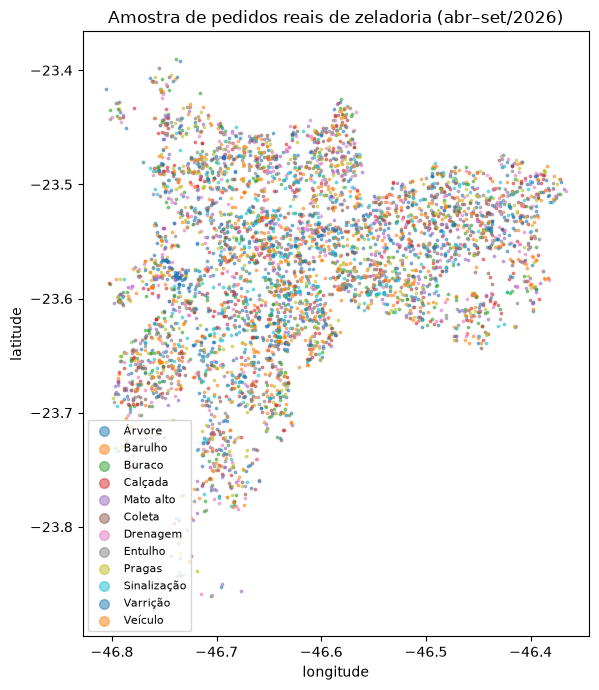

In [5]:
fig, eixo = plt.subplots(figsize=(7, 7))
for cat, g in mapa.groupby("categoria"):
    eixo.scatter(g["lon"], g["lat"], s=3, alpha=0.5, label=curto[cat])
eixo.set(title="Amostra de pedidos reais de zeladoria (abr–set/2026)", xlabel="longitude", ylabel="latitude")
eixo.set_aspect(1 / 0.917)
eixo.legend(markerscale=4, fontsize=8, loc="lower left")
fig.tight_layout()
fig.savefig(FIG / "dados_mapa.png", dpi=130)
plt.show()

## Limitações dos dados

- **Sem texto do cidadão:** a base publica a categoria escolhida, não o relato. Por isso o classificador é treinado com textos sintéticos (notebook 02).
- **Iluminação pública** não aparece nos dados abertos do SP156 e ficou fora do escopo.
- **Qualidade de origem:** trimestres com codificação, separador e formato de data diferentes; a coluna de subprefeitura traz valores que não são subprefeituras (ex.: "Prefeitura Regional nao encontrada"), excluídos; há nomes inconsistentes ("PERUS" e "PERUS-ANHANGUERA").
- **Prazo subestimado:** pedidos ainda abertos não entram no cálculo.
- **Privacidade:** coordenadas arredondadas para ~100 m antes de sair do processamento; o projeto não precisa do endereço exato.